<a href="https://colab.research.google.com/github/laksamanaap/244107020021-machine-leaning-course-2026-/blob/main/JS08/JS08_TugasLab1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.metrics import davies_bouldin_score

In [5]:
df = pd.read_csv('CC_Customer_Dataset.csv')

df.head()
print("Ukuran dataset:", df.shape)
print("\nInformasi dataset:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

Ukuran dataset: (660, 7)

Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No                660 non-null    int64
 1   Customer Key         660 non-null    int64
 2   Avg_Credit_Limit     660 non-null    int64
 3   Total_Credit_Cards   660 non-null    int64
 4   Total_visits_bank    660 non-null    int64
 5   Total_visits_online  660 non-null    int64
 6   Total_calls_made     660 non-null    int64
dtypes: int64(7)
memory usage: 36.2 KB

Missing values:
Sl_No                  0
Customer Key           0
Avg_Credit_Limit       0
Total_Credit_Cards     0
Total_visits_bank      0
Total_visits_online    0
Total_calls_made       0
dtype: int64


In [6]:
# Seleksi data
X = df[[
    'Avg_Credit_Limit',
    'Total_Credit_Cards',
    'Total_visits_bank',
    'Total_visits_online',
    'Total_calls_made'
]]

# Standardisasi data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Ukuran data setelah standardisasi:", X_scaled.shape)

Ukuran data setelah standardisasi: (660, 5)


In [7]:
# Membuat model agglomerative clustering dengan 3 kluster
model = AgglomerativeClustering(
    n_clusters=3,
    linkage='ward'
)

# Melakukan clustering
labels = model.fit_predict(X_scaled)

# Menambahkan hasil cluster ke dataset
df['Cluster'] = labels

# Melihat hasil clustering
df.head(10)

,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made,Cluster
0,1,87073,100000,2,1,1,0,0
1,2,38414,50000,3,0,10,9,1
2,3,17341,50000,7,1,3,4,0
3,4,40496,30000,5,1,1,4,0
4,5,47437,100000,6,0,12,3,2
5,6,58634,20000,3,0,1,8,1
6,7,48370,100000,5,0,11,2,2
7,8,37376,15000,3,0,1,1,1
8,9,82490,5000,2,0,2,2,1
9,10,44770,3000,4,0,1,7,1


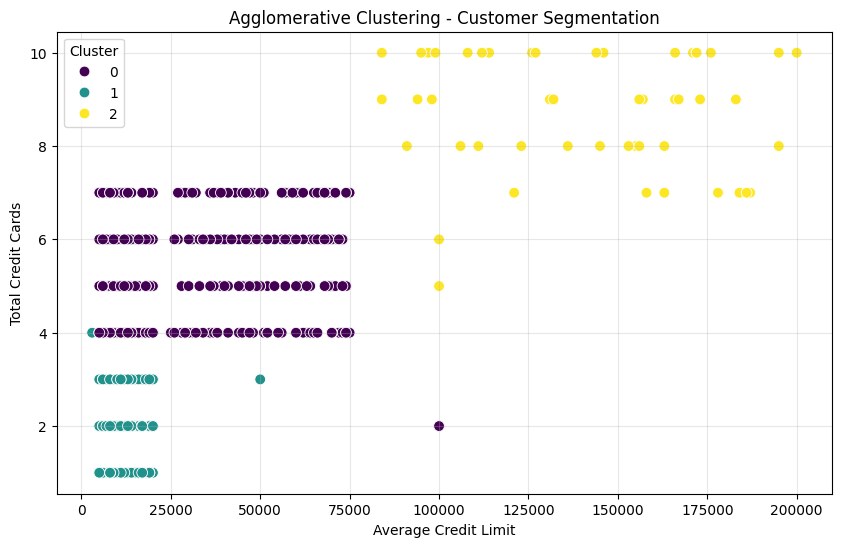

In [8]:
# Scatterplot hasil clustering
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Avg_Credit_Limit',
    y='Total_Credit_Cards',
    hue='Cluster',
    palette='viridis',
    s=60
)

plt.title('Agglomerative Clustering - Customer Segmentation')
plt.xlabel('Average Credit Limit')
plt.ylabel('Total Credit Cards')
plt.legend(title='Cluster')
plt.grid(alpha=0.3)
plt.show()

In [9]:
# Hitung silhouette score
sil_score = silhouette_score(X_scaled, labels)

# Hitung Davies Bouldin index
dbi_score = davies_bouldin_score(X_scaled, labels)

print("Silhouette score:", sil_score)
print("Davies Bouldin index:", dbi_score)

Silhouette score: 0.5147639589977819
Davies Bouldin index: 0.680959518994733


In [10]:
# Lihat anggota tiap cluster
print(df['Cluster'].value_counts().sort_index())

# Karakteristik
df.groupby('Cluster')[[
    'Avg_Credit_Limit',
    'Total_Credit_Cards',
    'Total_visits_bank',
    'Total_visits_online',
    'Total_calls_made'
]].mean().round(2)

Cluster
0    385
1    225
2     50
Name: count, dtype: int64


,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
Cluster,,,,,
0,33851.95,5.52,3.49,0.98,1.99
1,12151.11,2.42,0.94,3.55,6.86
2,141040.00,8.74,0.60,10.90,1.08


diperoleh tiga kelompok pelanggan dari total 660 data. Proses clustering menggunakan lima variabel, yaitu Avg_Credit_Limit, Total_Credit_Cards, Total_visits_bank, Total_visits_online, dan Total_calls_made

Hasil evaluasi menunjukkan nilai Silhouette score sebesar 0,5148 dan Davies Bouldin index sebesar 0,6810. Nilai tersebut menunjukkan bahwa model mampu membentuk kelompok pelanggan dengan pemisahan yang cukup baik. Dengan demikian, metode Agglomerative Clustering dapat digunakan untuk mengelompokkan pelanggan berdasarkan karakteristik penggunaan layanan dan batas kredit mereka